# Preprocessing Pipeline

Contains the preprocessing code for thesis by Aurelija Spunde.

Mainly based the pipeline is mainly based on Stropahl et al. (2018). The code on tutorials from MNE-Python documentation page (https://mne.tools/stable/auto_tutorials/intro/10_overview.html#preprocessing and other tutorials) and some parts are based on Luke Ring's code from github (https://github.com/NexusDynamic/RiseTogether-analysis/tree/main).

## Loading the data

Code from build.py

In [ ]:
"""

When the real data is available, can run this in the terminal to get the files


    parser.add_argument("--data-root", type=Path, default=Path("/work/RiseTogetherEEG/VideoGameParadigm-EEG/session_3"))
    parser.add_argument("--manifest", type=Path, default=Path("/work/RiseTogetherEEG/VideoGameParadigm-EEG/sessions.toml"))
    parser.add_argument("--xlsx", type=Path, default=None)
    parser.add_argument("--out", type=Path, default=Path("/work/analysis/data/session_3"))


pip install uv
git clone https://github.com/NexusDynamic/RiseTogether-analysis
cd RiseTogether-analysis

The BIDS format:

uv add mne numpy pandas mne-bids pyarrow
uv sync


"""

Loading the packages and the raw data

In [1]:
import mne
import sys
import os
import numpy as np
import pandas as pd
from pathlib import Path
import polars as pl
import matplotlib.pyplot as plt
# uv add ipympl

In [2]:
# Loading BIDS data

from rt_bids import read_session, read_recording, session_events, session_phases, crop_session, by_team, read_motion, to_session_time, from_session_time

root = "/work/RiseTogetherEEG/VideoGameParadigm-EEG"
raws = read_session(root, "session01")


In [3]:
# Define montage

montage = mne.channels.make_standard_montage('standard_1020')

In [4]:
for sub, raw in raws.items():
    print(raw.info)

<Info | 9 non-empty values
 bads: []
 ch_names: O1, Pz, P3, P7, CP1, CP5, M1, Cz, C3, T7, FC1, FC5, F3, F7, Fp1, ...
 chs: 29 EEG, 3 EOG
 custom_ref_applied: False
 highpass: 0.0 Hz
 line_freq: 50.0
 lowpass: 250.0 Hz
 meas_date: 1985-01-01 00:00:00 UTC
 nchan: 32
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>
<Info | 9 non-empty values
 bads: []
 ch_names: O1, Pz, P3, P7, CP1, CP5, M1, Cz, C3, T7, FC1, FC5, F3, F7, Fp1, ...
 chs: 29 EEG, 3 EOG
 custom_ref_applied: False
 highpass: 0.0 Hz
 line_freq: 50.0
 lowpass: 250.0 Hz
 meas_date: 1985-01-01 00:00:00 UTC
 nchan: 32
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>
<Info | 9 non-empty values
 bads: []
 ch_names: O1, Pz, P3, P7, CP1, CP5, M1, Cz, C3, T7, FC1, FC5, F3, F7, Fp1, ...
 chs: 29 EEG, 3 EOG
 custom_ref_applied: False
 highpass: 0.0 Hz
 line_freq: 50.0
 lowpass: 250.0 Hz
 meas_date: 1985-01-01 00:00:00 UTC
 nchan: 32
 projs: []
 sfreq

Processing sub-001...


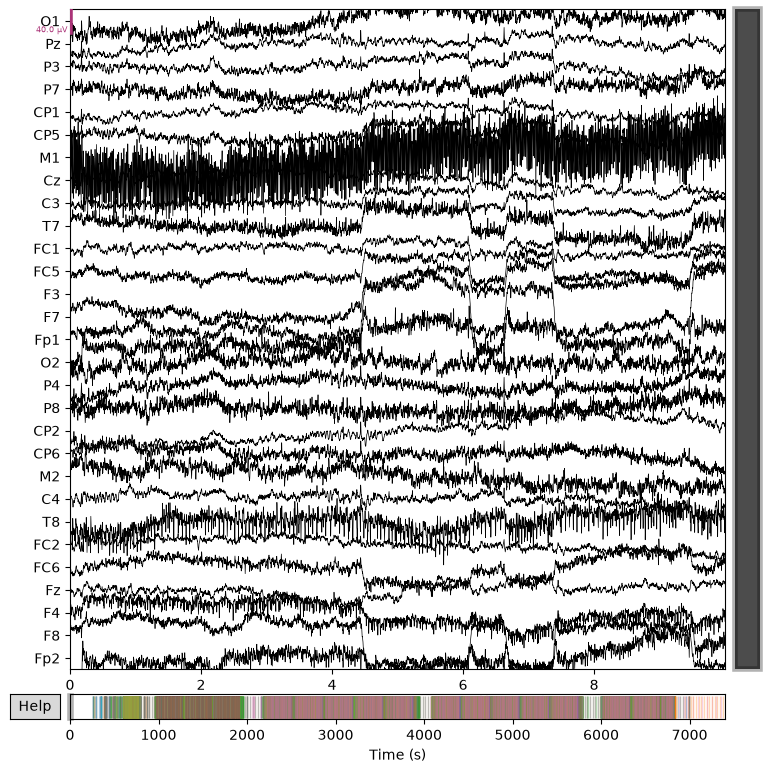

Processing sub-002...


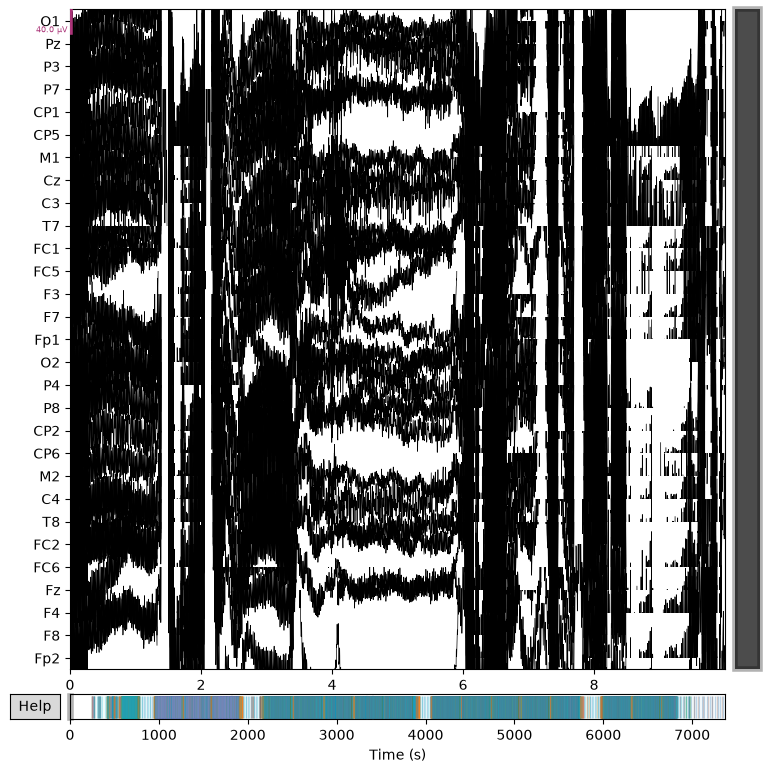

Processing sub-003...


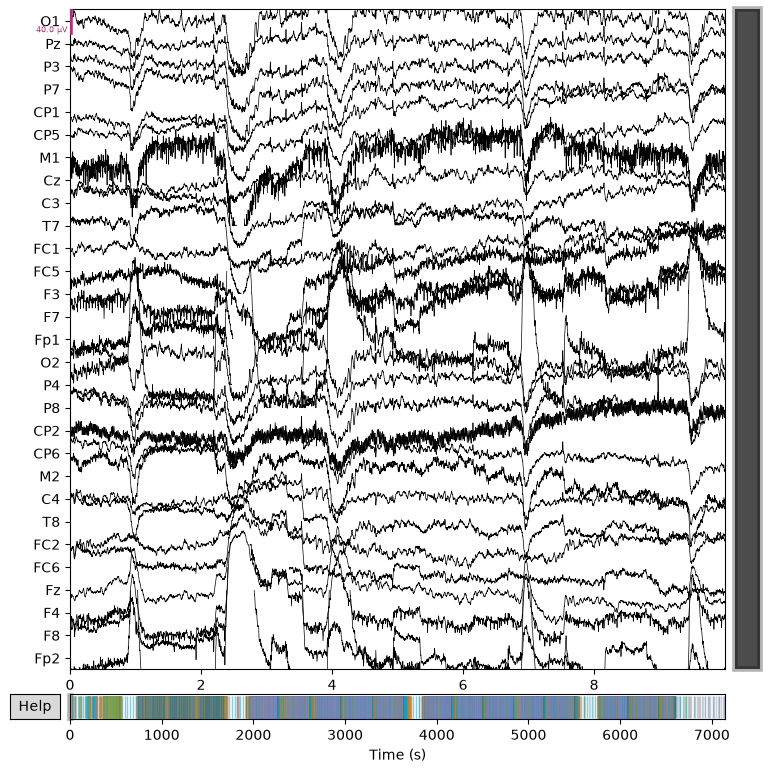

Processing sub-004...


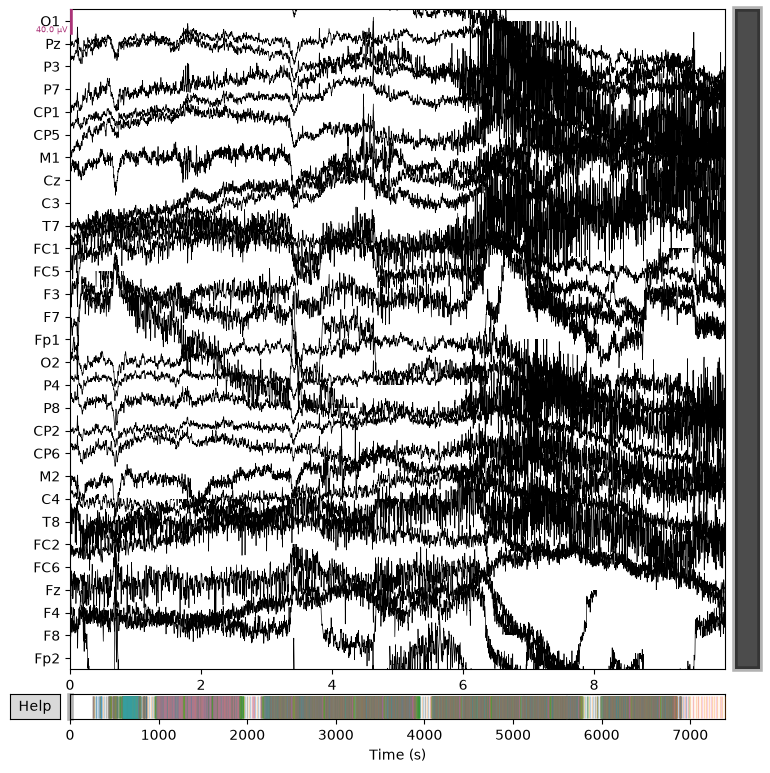

Processing sub-005...


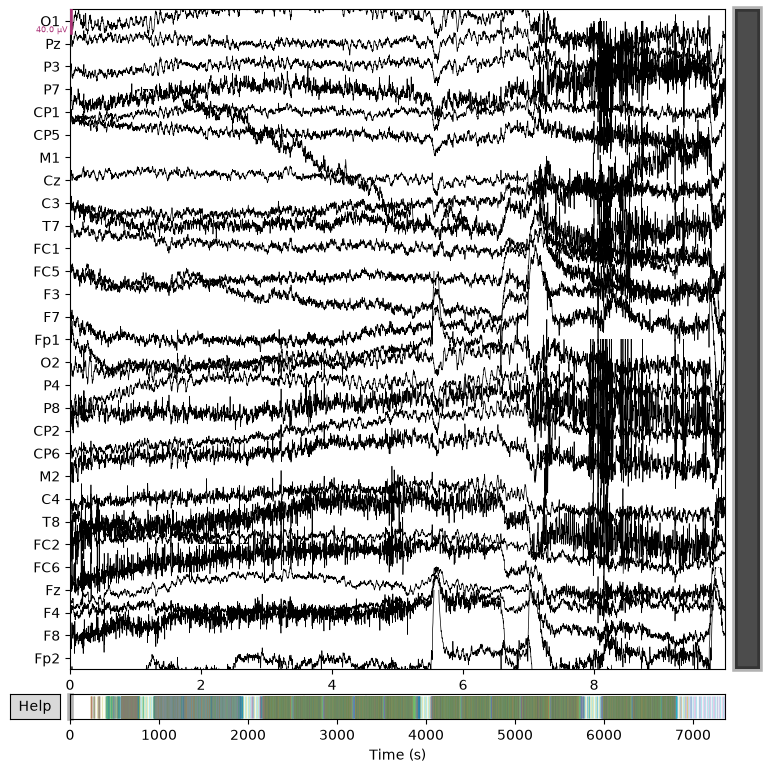

Processing sub-006...


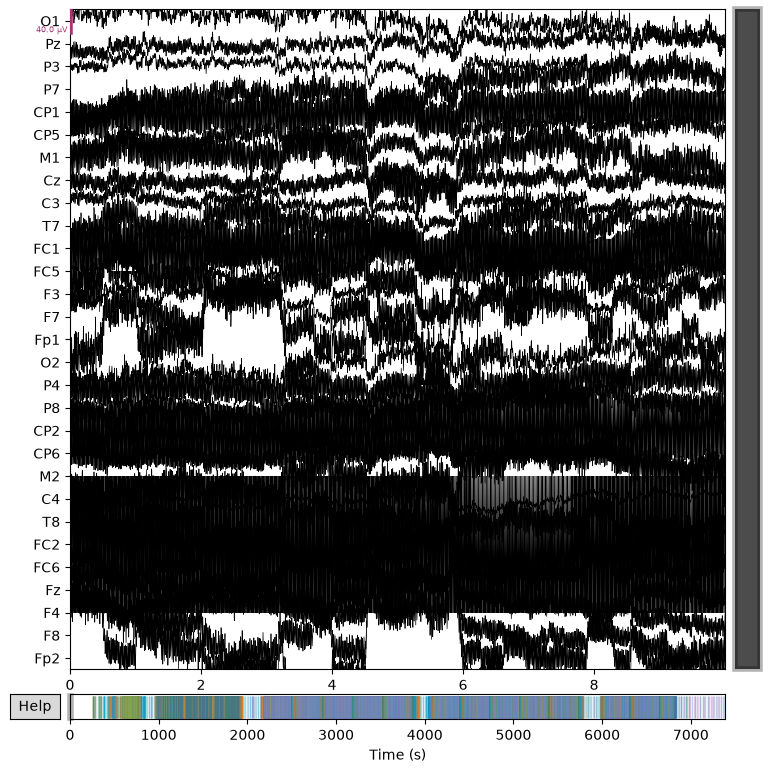

In [ ]:
for sub, raw in raws.items():
    print(f"Processing {sub}...")

    raw.set_montage(montage)
    raw.load_data()
    raw.pick("eeg")
    raw.plot(n_channels=29, title={sub})

Parameters

In [ ]:
FILTER_LOWPASS = 40.0  # Hz
FILTER_HIGHPASS = 1.0  # Hz


## ICA on raw data

**Looping over subjects:**

Filtering the data for ICA training

Epoching data and removing artificial epochs for ICA

Running ICA with the runica algorithm and the additional option of PCA

Saving ICA weights to original data


In [ ]:
for raw in raws: 

    # Identifying bad channels and interpolating them 

    raw.plot(n_channels=29, scalings='auto', block=True, title=f'Participant {raw.info["subject_id"]}')

    print(raw.info["bads"])

    if raw.info["bads"]:

        raw.interpolate_bads()

    raw.pick(['eeg'], exclude='bads')

    raw.set_eeg_reference("average") # or should i rereference it after the ICA?

    raw.plot(n_channels=30, scalings='auto', title="Cleaned EEG", block=True)

    # Filtering the data on a copy and saving it to a new file

    raw_filt = raw.copy().filter(l_freq=0.1, h_freq=FILTER_LOWPASS)

    # Notch filter
    raw_filt.notch_filter(freqs=50)

    # Plotting
    raw_filt.plot(n_channels=30, scalings=100e-6)

    file_name = f"sub-{subject_id}_filtered-raw.fif"
    save_path = os.path.join(filtered_data_folder, file_name)

    raw_filt.save(save_path, overwrite=True)
    print(f"Saved: {save_path}")

In [ ]:
raws_filtered = []

for subject in range(1, len(list(filtered_data_folder.glob("*.fif")))):
    raw_subject = mne.io.read_raw_fif(filtered_data_folder / f'{subject}_filtered-raw.fif')
    raws_filtered.append(raw_subject)

In [ ]:
# ICA

ica_output_folder = "work/analysis/preprocessed_data/ica_results"
os.makedirs(ica_output_folder, exist_ok=True)

for raw in raws_filtered:

    raw_ica = raw.copy()
    raw_ica.resample(250)

    ica = mne.preprocessing.ICA(n_components=len(raw.ch_names) - 1 - len(raw.info["bads"]), method="infomax", max_iter="auto", rng=97)
    ica.fit(raw_ica, reject=dict(eeg=200e-6))
    ica.plot_components()

    ica_filename = os.path.join(ica_output_folder, f"{raw.info['subject_id']}_raw-ica.fif")
    ica.save(ica_filename, overwrite=True)
    print(f"Saved ICA object: {ica_filename}")


In [ ]:
# Inspecting and plotting the ICA components for each subject

for raw in raws_filtered:

    ica_results = mne.preprocessing.read_ica(os.path.join(ica_output_folder, f"{raw.info['subject_id']}_raw-ica.fif"))

    ica.plot_sources(raw, block=True) # plotting and selecting the components to exclude (e.g., eye blink and movement artifacts) based on visual inspection
    ica.plot_components(inst=raw, block=True)

    print(f"{raw.info['subject_id']} marked bad components: {ica.exclude}")

    ica.save(os.path.join(ica_output_folder, f"{raw.info['subject_id']}_raw-ica.fif"), overwrite=True)

    raw = ica.apply(raw, exclude=ica.exclude)

# needs to be adjusted to manual selection
eog_inds, eog_scores = icas[0].find_bads_eog(raws[0], ch_name=['EOG2', 'EOG3', 'EOG4'])

template_eog_component = icas[0].get_components()[:, eog_inds[0]]
mne.preprocessing.corrmap(icas, template=template_eog_component, threshold='auto', plot=True)
print(template_eog_component)

for index, (ica, raw) in enumerate(zip(icas, raws)):
    with mne.viz.use_browser_backend("matplotlib"):
        fig = ica.plot_sources(raw, show_scrollbars=False)
    fig.subplots_adjust(top=0.9)
    fig.suptitle(f"Subject {index}")

## Preprocessing

**Preprocessing data after ICA cleaning:**

1. Detecting experimental events

2. Epoching

**1. Detecting experimental events**

In [ ]:
events = session_events(root, "session01")
print(events)

phases = session_phases(root, "session01") 
print(phases)

In [ ]:
event_dict = { # adjust to our events, figure out how to code the player activity
    "individual/balldrop": 1,
    "team/balldrop": 2,
    "individual/round_lost": 3,
    "team/round_lost": 4
}
    
fig = mne.viz.plot_events(
    events, event_id=event_dict, sfreq=raws_filtered[0].info["sfreq"], first_samp=raws_filtered[0].first_samp
)

**2. Epoching**

In [ ]:
reject_criteria = dict(eeg=100e-6)

conditions = ["individual/balldrop", "individual/round_lost", "team/balldrop", "team/round_lost"]

In [ ]:
for raw in raws_filtered:
    
    epochs = mne.Epochs(
        raw,
        events,
        event_id=event_dict,
        tmin=-0.2, # maybe look a bit before the balldrop event to see the anticipatory activity
        tmax=0.5,
        reject=reject_criteria,
        baseline=(-0.2, 0),
        preload=True,
    )


    epochs.equalize_event_counts(conditions)
    individual_epochs = epochs["individual"]
    team_epochs = epochs["team"]

    # Plotting

    individual_epochs.plot_image(picks=["EEG 021"])

    individual_evoked = individual_epochs.average()
    team_evoked = team_epochs.average()

    mne.viz.plot_compare_evokeds(
        dict(individual=individual_evoked, team=team_evoked),
        legend="upper left",
        show_sensors="upper right",
    )

    individual_evoked.plot_joint(picks="eeg")

    evoked_diff = mne.combine_evoked([individual_evoked, team_evoked], weights=[1, -1])
    evoked_diff.pick(picks="mag").plot_topo(color="r", legend=False)




Saving the pre-processed data

In [ ]:
for raw in raws_filtered:

    file_name = f"sub-{raw.info['subject_id']}_preprocessed-raw.fif"
    save_path = os.path.join(output_folder, file_name)

    raw.save(save_path, overwrite=True)
    print(f"Saved: {save_path}")

# Analysis

Loading the preprocessed data

In [ ]:
raws_preprocessed = []

for subject in range(1, len(list(output_folder.glob("*.fif")))):
    raw_subject = mne.io.read_raw_fif(output_folder / f'{subject}_preprocessed-raw.fif')
    raws_preprocessed.append(raw_subject)


Calculating player activity

In [ ]:
ACTION_COLOURS = {
    "left": "#4C72B0",
    "right": "#DD8452",
    "none": "#CCCCCC",
    "no press recorded": "#EEEEEE",
}
ACTION_ORDER = ["left", "right", "none", "no press recorded"]


trials = pl.read_parquet(args.out / "trials.parquet")
inputs = pl.read_parquet(args.out / "inputs.parquet")
participants = pl.read_parquet(args.out / "participants.parquet")
session = args.session
if session is None:
    found = sorted(trials["session_id"].unique())
    if len(found) > 1:
        print(f"several sessions in {args.out}: {found} -- pass --session to pick one")
        return 1
    session = found[0]
inputs = inputs.filter(pl.col("session_id") == session)


joint = inputs.filter(pl.col("condition") == "joint")
if joint.is_empty():
    print("  no joint-condition presses found; skipping figure 2")
    return

with_trials = joint.join(
    trials.select("session_id", "participant_uid", "trial_uid", "duration_s"),
    on=["session_id", "participant_uid", "trial_uid"],
    how="inner",
)

pressed = with_trials.group_by("round", "team_id", "participant_uid", "action").agg(
        pl.col("hold_s_trial").sum().alias("seconds")
    )


block_length = (
    trials.filter(pl.col("condition") == "joint")
    .with_columns(
        (
            (pl.col("t_end_wall") - pl.col("t_start_wall")).dt.total_microseconds()
            / 1e6
        ).alias("window_s")
    )
    .group_by("round", "participant_uid")
    .agg(
        pl.col("window_s").sum().alias("block_s"),
        # As it was for most of the block. Team membership is fixed within a
        # block, so the mode is the value; taking it here rather than from
        # `pressed` is what lets somebody who never pressed still be placed
        # on a team.
        pl.col("team_id").mode().first().alias("team_id"),
    )
)

played = with_trials.select("participant_uid", "trial_uid").unique()
silent = (
    trials.filter(pl.col("condition") == "joint")
    .select("participant_uid", "trial_uid")
    .join(played, on=["participant_uid", "trial_uid"], how="anti")
)
if silent.height:
    for uid, tuid in silent.sort("trial_uid", "participant_uid").rows():
        print(f"  note: {labels.get(uid, uid)} made no press at all in {tuid}")

rounds = sorted(cast(Iterable[int], block_length["round"].unique()))
    fig, axes = plt.subplots(
        1, len(rounds), figsize=(4.5 * len(rounds), 4.5), sharey=True, squeeze=False
    )

for ax, round_index in zip(axes[0], rounds):
    block = pressed.filter(pl.col("round") == round_index)
    roster = block_length.filter(pl.col("round") == round_index)
    lengths = dict(roster.select("participant_uid", "block_s").iter_rows())
    # Team 0 first, then team 1, so the teams read as two groups.
    people = (
        roster.sort("team_id", "participant_uid")
        .select("participant_uid", "team_id")
        .rows()
    )

    bottoms = [0.0] * len(people)
    for act in ACTION_ORDER:
        heights = []
        for i, (uid, _team) in enumerate(people):
            if act == "no press recorded":
                # Whatever the block did not account for. `inputs` records
                # changes, so nothing represents the paddle's state before
                # this person's first press of a trial -- normally neutral,
                # since input is blocked during the countdown. If somebody
                # never pressed at all, their whole trial lands here.
                heights.append(max(lengths.get(uid, 0.0) - bottoms[i], 0.0))
            else:
                match = block.filter(
                    (pl.col("participant_uid") == uid) & (pl.col("action") == act)
                )
                heights.append(match["seconds"].sum() if match.height else 0.0)
        ax.bar(
            range(len(people)),
            heights,
            bottom=bottoms,
            color=ACTION_COLOURS[act],
            label=act if round_index == rounds[0] else None,
            width=0.65,
        )
        bottoms = [b + h for b, h in zip(bottoms, heights)]

    ax.set_xticks(
        range(len(people)),
        [f"{labels.get(uid, uid)}\nteam {team}" for uid, team in people],
        fontsize=8,
    )
    # Colour the tick labels by team so the grouping is visible at a glance.
    for tick, (_uid, team) in zip(ax.get_xticklabels(), people):
        tick.set_color(TEAM_COLOURS.get(team, "#333333"))
    ax.set_title(f"Block {round_index + 1}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)

axes[0][0].set_ylabel("seconds in the block")
fig.suptitle(
    "Joint condition: time spent pressing left / right / nothing\n"
    "one bar per participant per block, all three trials summed",
    fontsize=11,
)
fig.tight_layout(rect=(0, 0.06, 1, 0.94))
fig.legend(
    loc="lower center", ncol=len(ACTION_ORDER), frameon=False, fontsize=9
)


RQ1a:     Is the amplitude of the FRN modulated by team play vs individual play? 

RQ1b: How does player engagement/activity measured as the time spent pressing the buttons modulate FRN amplitude? 